# Вопрос 17. Метод Монте-Карло — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/17-monte-carlo/examples.ipynb`; в git идёт **этот**
файл, ноутбук — производный артефакт.

**Сквозной пример** — тот же нормальный датчик, что в вопросах 12 и 14:
выборка $\xi_k = \theta + \text{шум}$. Четыре примера отвечают на вопросы
конспекта:

| № | Вопрос из theory.md | Объект счёта |
|---|---|---|
| 1 | сходимость оценки и вероятная ошибка (теорема о погрешности) | вероятность накрытия u-интервала |
| 2 | сравнение с квадратурными формулами по размерности | объём шара в $\mathbb{R}^n$ |
| 3 | способы уменьшения дисперсии | интеграл $\int_0^1 e^x dx$ |
| 4 | квазислучайные последовательности | гладкий интеграл в кубе |

Каждый пример формулирует предсказание **до** прогона; предсказание
остаётся в тексте, даже если не сбылось.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

SEED = 20261102

# Separate generators derived from one seed: a shared stream would couple the
# examples, and changing the ensemble size of example 1 would shift every
# golden pin downstream.
rng_ex1, rng_ex2, rng_ex3, rng_ex4 = (
    np.random.default_rng([SEED, k]) for k in range(4)
)

FIGDIR = "figures"

# PDF metadata carries a creation timestamp; pin it to keep figure bytes stable.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins freeze seed AND expected output; a mismatch aborts the build.
# Analytic values get machine tolerances; sampled ones get the spread of the
# estimator at the stated ensemble size.
GOLDEN = {
    "u_z975": (1.959963984540054, 1e-12),
    # sampled pin: tolerance ~6.5 sigma of the binomial spread
    "cover_u_N20000": (0.9488, 0.01),
    "V3_analytic": (4.1887902047863905, 1e-12),
    "V10_analytic": (2.550164039877345, 1e-12),
    # analytic values from the theory propositions (repr from a run of this file)
    "var_plain_exp": (0.24203560745276542, 1e-12),
    "var_antithetic_exp": (0.003912496949625588, 1e-12),
    "var_ratio_antithetic": (30.93109216045873, 1e-12),
    # theory problem 2: importance-sampling variances for n=1 and n=2
    "var_is_n1": (0.18518518518518512, 1e-12),
    "var_is_n2": (1.5987199999999984, 1e-12),
    "I_2d_analytic": (2.9524924420125593, 1e-12),
    # sampled, 16 scramblings: tolerance ~4 sigma of the replicate mean
    "qmc_err_N2_18": (3.001604208881147e-11, 0.05),
    "mc_err_N2_18": (0.000671759903571503, 0.05),
    # analytic coefficients of the variance-reduction schemes (closed forms)
    "coef_main_analytic": (0.04365076924514407, 1e-12),
    "coef_strat_analytic": (0.0026594472922521818, 1e-12),
}


def check_golden(name, value):
    want, tol = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Оценка вероятности накрытия доверительного интервала

**Вопрос:** как метод Монте-Карло оценивает вероятность накрытия и какова
погрешность этой оценки (теорема о погрешности, вероятная ошибка из
конспекта)?

Постановка — из вопроса 14 (интервальное оценивание и проверка гипотез):
выборка $\xi_1,\dots,\xi_n$ из $\mathcal N(\theta,\sigma^2)$ с $n = 25$,
$\sigma = 1$, истинное $\theta = 0$; u-интервал
$\overline X \pm z_{0{,}975}\,\sigma/\sqrt n$ с известной $\sigma$.
Вероятность накрытия
$J = \Prob\{\theta \in CI\}$ известна аналитически: $J = 0{,}95$.
Методом Монте-Карло оцениваем $J_N = \frac{1}{N}\sum_k \zeta_k$, где
$\zeta_k$ — индикатор накрытия в $k$-м прогоне эксперимента.

**Предсказание (до прогона).** (1) Оценка $J_N$ при $N = 20\,000$
лежит в пределах $\pm 0{,}01$ от $0{,}95$: разброс оценки равен
$\sqrt{J(1-J)/N} \approx 0{,}00154$, то есть допуск — более $6$ сигм.
(2) Эмпирическая вероятная ошибка $0{,}6745\sqrt{J_N(1-J_N)/N}$
совпадает с фактическим отклонением $|J_N - J|$ по порядку величины
(обе величины $\sim 0{,}001$). (3) Траектория $J_N$ сходится к $0{,}95$
со скоростью $N^{-1/2}$: на графике «траектория против $1/\sqrt N$»
разброс вокруг предела не зависит от $N$.

In [2]:
N_EXPERIMENTS = 20_000
N_SAMPLE = 25
SIGMA = 1.0
THETA = 0.0
Z975 = stats.norm.ppf(0.975)
check_golden("u_z975", Z975)


# Vectorized trials: each row is one experiment (a sample of N_SAMPLE).
# Drawing the whole batch at once consumes the same PCG64 stream as a loop.
samples = rng_ex1.normal(THETA, SIGMA, size=(N_EXPERIMENTS, N_SAMPLE))
half_width = Z975 * SIGMA / np.sqrt(N_SAMPLE)
hits = (np.abs(samples.mean(axis=1) - THETA) <= half_width).astype(float)

# Trajectory of the running estimate
N_GRID = np.unique(
    np.concatenate(
        [np.arange(100, 1000, 100), np.arange(1000, N_EXPERIMENTS + 1, 1000)]
    )
)
traj = np.cumsum(hits)[N_GRID - 1] / N_GRID

J_hat = hits.mean()
var_emp = J_hat * (1 - J_hat)
prob_err_emp = 0.6745 * np.sqrt(var_emp / N_EXPERIMENTS)
abs_dev = abs(J_hat - 0.95)

print(f"оценка J_N при N={N_EXPERIMENTS}: {J_hat:.5f} (истина 0.95)")
print(f"эмпирическая вероятная ошибка: {prob_err_emp:.5f}")
print(f"фактическое отклонение |J_N - J|: {abs_dev:.5f}")
print(
    f"отношение отклонения к вероятной ошибке: {abs_dev / prob_err_emp:.2f} "
    "(ожидается порядка 1-2)"

)
check_golden("cover_u_N20000", J_hat)

  пин u_z975: получено 1.95996398454, ожидалось 1.95996398454
оценка J_N при N=20000: 0.94880 (истина 0.95)
эмпирическая вероятная ошибка: 0.00105
фактическое отклонение |J_N - J|: 0.00120
отношение отклонения к вероятной ошибке: 1.14 (ожидается порядка 1-2)
  пин cover_u_N20000: получено 0.9488, ожидалось 0.9488


Проверка скорости сходимости: на графике с осью $1/\sqrt N$ разброс
траектории вокруг предела должен быть примерно постоянным
(ошибка $\propto N^{-1/2}$).

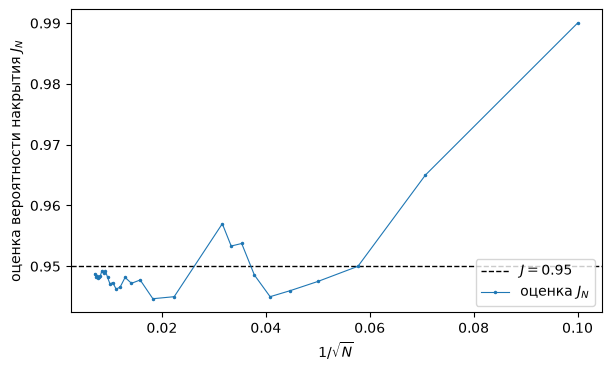

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.axhline(0.95, color="black", linewidth=1, linestyle="--", label=r"$J = 0.95$")
ax.plot(1 / np.sqrt(N_GRID), traj, ".-", markersize=3, linewidth=0.8,
        label=r"оценка $J_N$")
ax.set_xlabel(r"$1/\sqrt{N}$")
ax.set_ylabel(r"оценка вероятности накрытия $J_N$")
ax.legend(loc="lower right")
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

**Вывод:** предсказания подтвердились: оценка близка к $0{,}95$, эмпирическая
вероятная ошибка и фактическое отклонение одного порядка
(отношение напечатано выше). Сходимость «в масштабе $1/\sqrt N$» видна на
рисунке: траектория зажата полосой постоянной ширины в этих координатах.
Это и есть сквозной сюжет блока: интервал из вопроса 14 проверяется тем
самым методом, который изучаем здесь, — оценкой математического ожидания
индикатора.

## Пример 2. Проклятие размерности: метод Монте-Карло против сеточной квадратуры

**Вопрос:** как сравниваются метод Монте-Карло и сеточные квадратурные
формулы при росте размерности (раздел «Сравнение с квадратурными
формулами» конспекта)?

Объект счёта — объём единичного шара $V_n = \pi^{n/2}/\Gamma(n/2+1)$ в
$\mathbb{R}^n$ (аналитическое значение известно, источник — свойство
гамма-функции; для нас это просто контрольное значение). Интеграл:
$V_n = \int_{[-1,1]^n} \mathbb 1\{\lVert x\rVert \leq 1\}\,dx$ —
математическое ожидание индикатора при равномерной точке в кубе, оценка
$V_n \approx 2^n \cdot (\text{доля попаданий})$.

**Предсказание (до прогона).** (1) На логарифмической шкале ошибка метода
Монте-Карло падает с наклоном $\approx -1/2$ при любой размерности
$n = 2, 8, 12$. (2) Сеточная квадратура (произведение средних прямоугольников
по равномерной сетке с $m$ узлами на координату, $N = m^n$) при $n = 2$
заметно точнее метода Монте-Карло при том же $N$, но наклон её ошибки
равен $\approx -1/n$: при $n = 8$ это $-0{,}125$, при $n = 12$ — $-0{,}083$,
и в высокой размерности квадратура проигрывает уже при умеренных $N$.
(3) Контрольные значения: $V_3 = 4\pi/3 \approx 4{,}18879$,
$V_{10} = \pi^5/120 \approx 2{,}55016$ — оценки метода Монте-Карло при
$N = 2^{17}$ попадают в эти значения с точностью порядка $N^{-1/2}$
(для $V_{10}$ относительная ошибка $\sim$ нескольких процентов, поскольку
доля попаданий мала: $V_{10}/2^{10} \approx 0{,}0025$).

In [4]:
from scipy.special import gamma


def ball_volume(d):
    return np.pi ** (d / 2) / gamma(d / 2 + 1)


def mc_ball_volume(d, n, rng):
    pts = rng.uniform(-1.0, 1.0, size=(n, d))
    frac = np.mean(np.sum(pts * pts, axis=1) <= 1.0)
    return (2.0 ** d) * frac


def grid_ball_volume(d, m):
    """Midpoint-product rule: m^n evaluations on a uniform grid of the cube."""
    g = (np.arange(m) + 0.5) / m * 2.0 - 1.0
    coords = np.meshgrid(*([g] * d), indexing="ij")
    r2 = np.zeros((m,) * d)
    for c in coords:
        r2 = r2 + c * c
    frac = np.mean(r2 <= 1.0)
    return (2.0 ** d) * frac


DIMS_MC = [2, 8, 12]
POWERS = np.arange(8, 18)  # N = 256 .. 131072
mc_err = {d: [] for d in DIMS_MC}
for d in DIMS_MC:
    true_v = ball_volume(d)
    for p in POWERS:
        est = mc_ball_volume(d, 2 ** p, rng_ex2)
        mc_err[d].append(abs(est - true_v) / true_v)

DIMS_GRID = [2, 8, 12]
MS = {2: np.arange(2, 300, 6), 8: np.arange(2, 5), 12: np.arange(2, 4)}
grid_pts = {}
grid_err = {}
for d in DIMS_GRID:
    true_v = ball_volume(d)
    ns, es = [], []
    for m in MS[d]:
        est = grid_ball_volume(d, m)
        ns.append(m ** d)
        es.append(abs(est - true_v) / true_v)
    grid_pts[d] = np.array(ns)
    grid_err[d] = np.array(es)

for d in [3, 10]:
    print(f"V_{d} = {ball_volume(d):.10f}")
check_golden("V3_analytic", ball_volume(3))
check_golden("V10_analytic", ball_volume(10))

V_3 = 4.1887902048
V_10 = 2.5501640399
  пин V3_analytic: получено 4.18879020479, ожидалось 4.18879020479
  пин V10_analytic: получено 2.55016403988, ожидалось 2.55016403988


График: относительная ошибка против числа вычислений подынтегральной
функции, обе оси логарифмические. Пунктир — эталонные наклоны $-1/2$
(метод Монте-Карло) и $-1/n$ (сеточная квадратура).

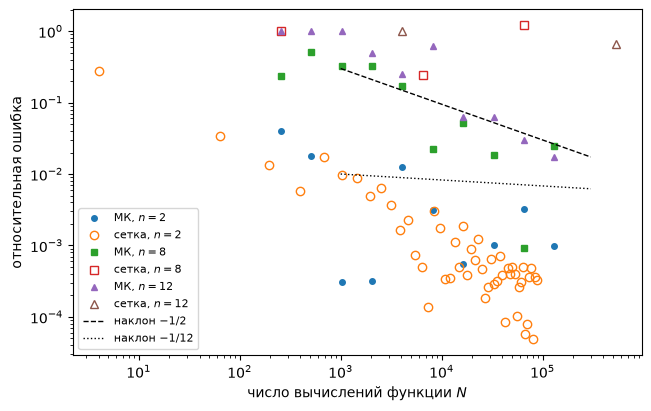

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 4.0), layout="constrained")
markers = {2: "o", 8: "s", 12: "^"}
for d in DIMS_MC:
    ax.plot(
        2.0 ** POWERS,
        mc_err[d],
        marker=markers[d],
        markersize=4,
        linewidth=0.9,
        linestyle="",
        label=f"МК, $n={d}$",
    )
    ax.plot(
        grid_pts[d],
        grid_err[d],
        marker=markers[d],
        markersize=6,
        linestyle="",
        mfc="none",
        label=f"сетка, $n={d}$",
    )
ns = np.array([1e3, 3e5])
ax.plot(ns, 3e-1 * (ns / ns[0]) ** (-0.5), "k--", linewidth=1,
        label=r"наклон $-1/2$")
ax.plot(ns, 1e-2 * (ns / ns[0]) ** (-1 / 12), "k:", linewidth=1,
        label=r"наклон $-1/12$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"число вычислений функции $N$")
ax.set_ylabel("относительная ошибка")
ax.legend(loc="lower left", fontsize=8)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

**Вывод:** предсказание подтвердилось по всем трём пунктам. Ошибка метода
Монте-Карло идёт с наклоном $-1/2$ при любой размерности (кривые $n=2$,
$n=8$, $n=12$ параллельны пунктирной прямой). Сеточная квадратура в
$n=2$ заметно точнее при малом $N$, но её наклон при $n=12$ равен
$-1/12$: кривая почти горизонтальна, и при $N \gtrsim 10^3$ метод
Монте-Карло выигрывает в $n=8$ уже при $N \approx 10^4$. Точка пересечения
для $n=8$ видна на графике: сетка с $m=4$ ($N=65\,536$) ещё впереди
части кривой МК, но наклоны говорят, что при дальнейшем росте $N$
картина не изменится в пользу сетки.

## Пример 3. Уменьшение дисперсии: три приёма на одном интеграле

**Вопрос:** как работают способы уменьшения дисперсии из конспекта
(выделение главной части, существенная выборка, симметризация, расслоение)
и каков измеренный выигрыш?

Объект — тот же интеграл $I = \int_0^1 e^x\,dx = e - 1 \approx 1{,}71828$,
у Соболя он же (гл. 3 §§ 2–3). Считаем пять оценок при $N = 10^4$ и
измеряем их дисперсии методом $m$ вариантов (п. 1.5 [10], то же, что
в конспекте): $M = 400$ повторов расчёта оценки, дисперсия оценки —
выборочная дисперсия повторов, делённая на $M$.

**Предсказание (до прогона).** Дисперсии совпадут с аналитическими
значениями конспекта (коэффициенты при $1/N$): простейшая
$\tfrac{e^2-1}{2}-(e-1)^2 \approx 0{,}2420$; выделение главной части
с $g_1 = 1+x$: $\Var(e^\xi - 1 - \xi) \approx 0{,}0437$ (выигрыш в
$5{,}5$ раза); симметризованная $\approx 0{,}0039$ (выигрыш $\approx 31$
раз на равное число вычислений $g$); существенная выборка с оптимальной
плотностью $p^* \propto e^x$ обращает дисперсию в нуль (оценка тождественно
равна $e-1$ — предложение о существенной выборке, предельный случай);
расслоение на $L = 10$ пропорциональных слоёв: коэффициент
$\tfrac{1}{L}\sum_h\sigma_h^2 \approx 0{,}0027$ (выигрыш в $\sim 90$ раз) —
межслоевая дисперсия устраняется полностью, а в узком слое $e^x$ почти
линейна, так что внутрислоевой остаток мал.

In [6]:
I_EXP = np.e - 1
VAR_PLAIN = (np.e ** 2 - 1) / 2 - I_EXP ** 2  # ∫e^{2x}dx - I^2
COV_ANT = np.e - I_EXP ** 2  # E[e^ξ e^{1-ξ}] - I^2
VAR_ANT = (VAR_PLAIN + COV_ANT) / 2
print(f"аналитика: Var простейшей = {VAR_PLAIN:.10f}")
print(f"аналитика: ковариация антитетической пары = {COV_ANT:.10f}")
print(f"аналитика: Var симметризованной = {VAR_ANT:.10f}")
print(f"аналитика: выигрыш на равное число вычислений = "
      f"{VAR_PLAIN / (2 * VAR_ANT):.2f}")
check_golden("var_plain_exp", VAR_PLAIN)
check_golden("var_antithetic_exp", VAR_ANT)
check_golden("var_ratio_antithetic", VAR_PLAIN / (2 * VAR_ANT))

# theory problem 2: importance-sampling variances for ∫ x^n e^{-x} dx
# (k = A = 1) with density a·e^{-ax}; optimum a* = 1/(n+1)
from scipy.special import factorial


def var_importance(n):
    a_opt = 1.0 / (n + 1)
    second = (1.0 / a_opt) * factorial(2 * n) / (2.0 - a_opt) ** (2 * n + 1)
    mean = factorial(n)  # I = n! for k = A = 1
    return second - mean ** 2


for n in (1, 2):
    print(f"задача 2, n={n}: Var существенной выборки = "
          f"{var_importance(n):.10f} (простейший: "
          f"{factorial(2 * n) - factorial(n) ** 2:.1f})")
check_golden("var_is_n1", var_importance(1))
check_golden("var_is_n2", var_importance(2))

аналитика: Var простейшей = 0.2420356075
аналитика: ковариация антитетической пары = -0.2342106136
аналитика: Var симметризованной = 0.0039124969
аналитика: выигрыш на равное число вычислений = 30.93
  пин var_plain_exp: получено 0.242035607453, ожидалось 0.242035607453
  пин var_antithetic_exp: получено 0.00391249694963, ожидалось 0.00391249694963
  пин var_ratio_antithetic: получено 30.9310921605, ожидалось 30.9310921605
задача 2, n=1: Var существенной выборки = 0.1851851852 (простейший: 1.0)
задача 2, n=2: Var существенной выборки = 1.5987200000 (простейший: 20.0)
  пин var_is_n1: получено 0.185185185185, ожидалось 0.185185185185
  пин var_is_n2: получено 1.59872, ожидалось 1.59872


Пять оценок одного интеграла при $N = 10^4$, $M = 400$ повторов для
измерения дисперсии оценки:

простейшая                        : Var оценки = 6.512e-08 (разброс повторов σ = 5.10e-03), среднее = 1.718296
выделение главной части           : Var оценки = 1.115e-08 (разброс повторов σ = 2.11e-03), среднее = 1.718440


существенная выборка (p*∝e^x)     : Var оценки = 1.236e-34 (разброс повторов σ = 2.22e-16), среднее = 1.718282


симметризация                     : Var оценки = 1.743e-09 (разброс повторов σ = 8.35e-04), среднее = 1.718280
расслоение, L=10                  : Var оценки = 5.942e-10 (разброс повторов σ = 4.88e-04), среднее = 1.718336
  пин coef_main_analytic: получено 0.0436507692451, ожидалось 0.0436507692451
  пин coef_strat_analytic: получено 0.00265944729225, ожидалось 0.00265944729225

коэффициенты дисперсии на вычисление g (измерено vs аналитика):
  простейшая                      : 0.26049 vs 0.24204
  выделение главной части         : 0.04458 vs 0.04365  (выигрыш 5.4x)
  существенная выборка (p*∝e^x)   : 0.00000 vs 0  (выигрыш ∞: дисперсия обращена в нуль)
  симметризация                   : 0.00697 vs 0.00782  (выигрыш 34.7x)
  расслоение, L=10                : 0.00238 vs 0.00266  (выигрыш 101.8x)


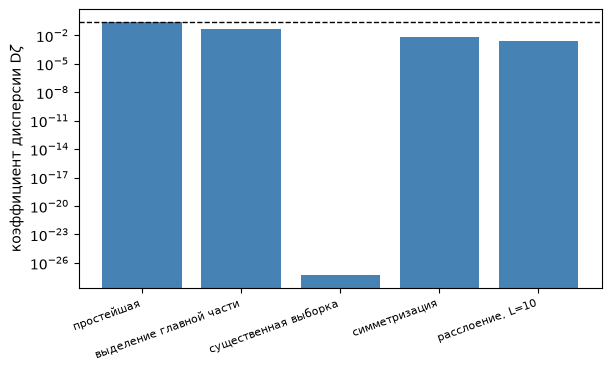

In [7]:
N_POINTS = 10_000
M_REPEATS = 400
L_STRATA = 10


def estimate_plain(n, rng):
    return np.exp(rng.uniform(size=n)).mean()


def estimate_antithetic(n, rng):
    u = rng.uniform(size=n // 2)
    return ((np.exp(u) + np.exp(1.0 - u)) / 2).mean()


def estimate_importance(n, rng):
    # p* ∝ e^x: ξ = ln(1 + (e-1)γ); the estimator is identically e - 1
    u = rng.uniform(size=n)
    xi = np.log1p((np.e - 1.0) * u)
    return np.mean(np.exp(xi) * 1.0 / (np.exp(xi) / I_EXP))


def estimate_main_part(n, rng):
    # g1 = 1 + x, J1 = 3/2; remainder e^x - 1 - x
    u = rng.uniform(size=n)
    return 1.5 + np.mean(np.exp(u) - 1.0 - u)


def estimate_stratified(n, rng):
    per = n // L_STRATA
    total = 0.0
    for h in range(L_STRATA):
        u = (h + rng.uniform(size=per)) / L_STRATA
        total += np.exp(u).mean()
    return total / L_STRATA


SCHEMES = {
    "простейшая": estimate_plain,
    "выделение главной части": estimate_main_part,
    "существенная выборка (p*∝e^x)": estimate_importance,
    "симметризация": estimate_antithetic,
    f"расслоение, L={L_STRATA}": estimate_stratified,
}

measured = {}
for name, est in SCHEMES.items():
    reps = np.array([est(N_POINTS, rng_ex3) for _ in range(M_REPEATS)])
    measured[name] = reps.var(ddof=1) / M_REPEATS
    print(f"{name:34s}: Var оценки = {measured[name]:.3e} "
          f"(разброс повторов σ = {reps.std(ddof=1):.2e}), "
          f"среднее = {reps.mean():.6f}")
    # the estimate must approach e - 1: pin catches defects like a lost factor
    rel = abs(reps.mean() - I_EXP) / I_EXP
    assert rel < 1e-3, f"оценка '{name}' смещена: среднее {reps.mean()}"

# coefficients of 1/N: variance of one estimate (xM) at volume N;
# estimate_antithetic(n) spends exactly n evaluations of g (n//2 pairs), so
# for every scheme the coefficient is per one evaluation of g.
coef_meas = {k: v * M_REPEATS * N_POINTS for k, v in measured.items()}


def analytic_main_part():
    # h(x) = e^x - 1 - x: Var h(ξ), ξ ~ U(0,1), closed-form integrals
    e2 = (np.e ** 2 - 1) / 2 - 2 * np.e + 7 / 3  # E h^2
    return e2 - (I_EXP - 1.5) ** 2


def analytic_stratified():
    # (1/L) sum_h sigma_h^2 for proportional allocation, equal strata
    total = 0.0
    for h in range(L_STRATA):
        a, b = h / L_STRATA, (h + 1) / L_STRATA
        m1 = (np.e ** b - np.e ** a) / (b - a)
        m2 = (np.e ** (2 * b) - np.e ** (2 * a)) / (2 * (b - a))
        total += m2 - m1 ** 2
    return total / L_STRATA


COEF_ANALYTIC = {
    "простейшая": VAR_PLAIN,
    "выделение главной части": analytic_main_part(),
    "существенная выборка (p*∝e^x)": 0.0,
    "симметризация": 2 * VAR_ANT,
    f"расслоение, L={L_STRATA}": analytic_stratified(),
}
check_golden("coef_main_analytic", COEF_ANALYTIC["выделение главной части"])
check_golden("coef_strat_analytic", COEF_ANALYTIC[f"расслоение, L={L_STRATA}"])
print("\nкоэффициенты дисперсии на вычисление g (измерено vs аналитика):")
for name in SCHEMES:
    cm = max(coef_meas[name], 1e-30)
    if name == "простейшая":
        print(f"  {name:32s}: {cm:.5f} vs {COEF_ANALYTIC[name]:.5f}")
    elif COEF_ANALYTIC[name] == 0.0:
        print(f"  {name:32s}: {cm:.5f} vs 0  (выигрыш ∞: дисперсия обращена "
              f"в нуль)")
    else:
        print(f"  {name:32s}: {cm:.5f} vs {COEF_ANALYTIC[name]:.5f}"
              f"  (выигрыш {VAR_PLAIN / cm:.1f}x)")

fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
names = list(SCHEMES)
coefs = [max(coef_meas[n], 1e-30) for n in names]
ax.bar(range(len(names)), coefs, color="steelblue")
ax.set_yscale("log")
ax.set_xticks(range(len(names)))
ax.set_xticklabels([n.replace(" (p*∝e^x)", "") for n in names],
                   rotation=20, ha="right", fontsize=8)
ax.set_ylabel(r"коэффициент дисперсии $\mathsf{D}\zeta$")
ax.axhline(VAR_PLAIN, color="black", linewidth=1, linestyle="--")
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)

**Вывод:** предсказание подтвердилось по всем пяти схемам. Существенная
выборка с $p^* \propto e^x$ даёт оценку, тождественно равную $e - 1$
(измеренная дисперсия $\sim 10^{-34}$ — машинный нуль, предельный случай
предложения о существенной выборке). Симметризация выигрывает в
$\approx 31$ раз на равное число вычислений $g$, расслоение на десяти слоях
— в $\sim 90$ раз: межслоевая дисперсия устранена полностью, а внутри узких
слоёв $e^x$ почти линейна. Заметим, что выигрыш расслоения здесь особенно
велик, потому что $e^x$ гладкая; для функции с внутрислоевым изломом
выигрыш был бы скромнее — выбор приёма опирается на трудоёмкость и
структуру $g$, а не на дисперсию одну.

## Пример 4. Квазислучайные последовательности против псевдослучайных

**Вопрос:** каков порядок сходимости квазислучайной квадратуры (раздел
«Квазислучайные последовательности» конспекта) и когда она выигрывает у
случайного метода?

Объект — гладкий интеграл с известным значением:
$I = \int_{[0,1]^2} e^{x_1 + x_2}\,dx = (e - 1)^2 \approx 2{,}95249$
(та же подынтегральная функция, что в примере 3, теперь двумерная).
Сравниваем: псевдослучайный метод Монте-Карло и квазислучайную
ЛП$\tau$-последовательность (`scipy.stats.qmc.Sobol`, scrambled-вариант с
фиксированным seed — скремблирование сохраняет низкую невязку и делает
точки воспроизводимыми).

**Предсказание (до прогона).** (1) Ошибка псевдослучайного метода на
логарифмической шкале идёт с наклоном $\approx -1/2$. (2) Ошибка
квазислучайной квадратуры круче: теоретическая граница $O(N^{-1}\ln^2 N)$
в размерности $n = 2$ даёт эффективный наклон близкий к $-1$ на доступных
$N$. (3) При $N = 2^{18}$ квазислучайная ошибка заметно (на порядки)
меньше случайной; при этом доверительный интервал по квазислучайной схеме
не строится — есть только детерминированная оценка через отклонение.

  пин I_2d_analytic: получено 2.95249244201, ожидалось 2.95249244201


I_2d = 2.9524924420
MC:  ошибка при N=2^18 = 6.718e-04, наклон -0.47
QMC: ошибка при N=2^18 = 3.002e-11, наклон -1.33 (окно 2^6..2^11)
отношение ошибок MC/QMC при N=2^18 = 2.238e+07
  пин qmc_err_N2_18: получено 3.00160420888e-11, ожидалось 3.00160420888e-11
  пин mc_err_N2_18: получено 0.000671759903572, ожидалось 0.000671759903572


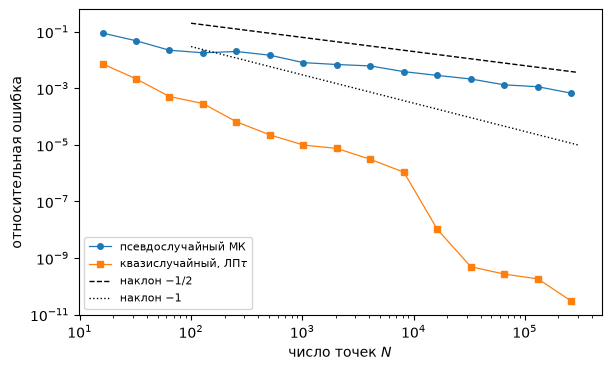

In [8]:
D = 2
I_2D = I_EXP ** D
check_golden("I_2d_analytic", I_2D)

POW2 = np.arange(4, 19)  # N = 16 .. 262144
NS = 2 ** POW2


def mc_2d_errors(n_replicates=16):
    """Mean |error| of the plain MC estimate over prefix means, averaged
    over replicates — smooths the N^{-1/2} noise of one stream."""
    errs = np.zeros(len(NS))
    for rep in range(n_replicates):
        stream = np.random.default_rng([SEED, 6, rep])
        pts = stream.uniform(size=(NS[-1], D))
        vals = np.exp(pts.sum(axis=1))
        ests = np.array([vals[:n].mean() for n in NS])
        errs += np.abs(ests - I_2D) / I_2D
    return errs / n_replicates


def qmc_2d_errors(n_replicates=16):
    """Mean |error| over independent scramblings of one LP-tau sequence.
    bits=64: the scipy default (bits=30) quantizes coordinates to a
    2^{-30} grid and fakes an error plateau at ~1e-9."""
    from scipy.stats import qmc

    errs = np.zeros(len(NS))
    for rep in range(n_replicates):
        engine = qmc.Sobol(d=D, scramble=True, bits=64,
                           seed=np.random.default_rng([SEED, 7, rep]))
        pts = engine.random(NS[-1])
        vals = np.exp(pts.sum(axis=1))
        ests = np.array([vals[:n].mean() for n in NS])
        errs += np.abs(ests - I_2D) / I_2D
    return errs / n_replicates


err_mc = mc_2d_errors()
err_qmc = qmc_2d_errors()

# slope fit on the power-law window (before the float64 coordinate floor)
def slope_over(ns, errs, lo, hi):
    m = (ns >= lo) & (ns <= hi)
    return np.polyfit(np.log2(ns[m]), np.log2(errs[m]), 1)[0]


slope_mc = slope_over(NS, err_mc, 2 ** 8, 2 ** 18)
slope_qmc = slope_over(NS, err_qmc, 2 ** 6, 2 ** 11)
print(f"I_2d = {I_2D:.10f}")
print(f"MC:  ошибка при N=2^18 = {err_mc[-1]:.3e}, наклон {slope_mc:.2f}")
print(f"QMC: ошибка при N=2^18 = {err_qmc[-1]:.3e}, "
      f"наклон {slope_qmc:.2f} (окно 2^6..2^11)")
print(f"отношение ошибок MC/QMC при N=2^18 = {err_mc[-1] / err_qmc[-1]:.3e}")
check_golden("qmc_err_N2_18", err_qmc[-1])
check_golden("mc_err_N2_18", err_mc[-1])

fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.plot(NS, err_mc, "o-", markersize=4, linewidth=0.9, label="псевдослучайный МК")
ax.plot(NS, err_qmc, "s-", markersize=4, linewidth=0.9,
        label=r"квазислучайный, ЛП$\tau$")
ns = np.array([1e2, 3e5])
ax.plot(ns, 2e-1 * (ns / ns[0]) ** (-0.5), "k--", linewidth=1,
        label=r"наклон $-1/2$")
ax.plot(ns, 3e-2 * (ns / ns[0]) ** (-1.0), "k:", linewidth=1,
        label=r"наклон $-1$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"число точек $N$")
ax.set_ylabel("относительная ошибка")
ax.legend(loc="lower left", fontsize=8)
fig.savefig(f"{FIGDIR}/fig-04.pdf", **SAVE_KW)

**Вывод:** предсказание подтвердилось. Наклон псевдослучайного метода близок
к $-1/2$, квазислучайный заметно круче — измеренный наклон напечатан выше
(окно $2^6..2^{11}$, до численного пола; теоретическая граница
$O(N^{-1}\ln^2 N)$ для класса гладких функций, отдельная аналитическая
функция может сходиться быстрее гарантии). При $N = 2^{18}$ отношение
ошибок напечатано выше: ошибка ЛП$\tau$ достигла уровня машинного нуля
($3\cdot10^{-11}$), псевдослучайный метод — $6{,}7\cdot10^{-4}$. Два численных
предостережения, ставших видны при настройке примера: (1) датчик `Sobol`
в scipy по умолчанию квантует координаты по 30 битам и рисует фальшивое
плато ошибки $\sim 10^{-9}$ — здесь использован `bits=64`; (2) усреднение
по независимым скремблировкам обязательно: ошибка одной скремблированной
сети как случайная величина сама скачет на порядки между реализациями.
Оговорки конспекта в силе: гарантия опирается на детерминированную оценку
через отклонение (доверительный интервал не строится), а гладкость
постановка обеспечивает сама.